In [1]:
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

ValueError: x and y must have same first dimension, but have shapes (100,) and (1,)

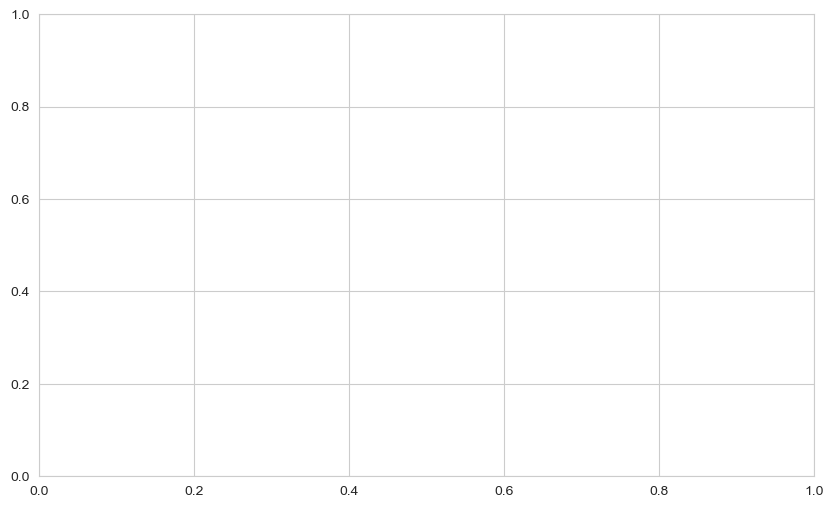

In [6]:
x = np.linspace(-2, 2, 100)

plt.figure(figsize=(10, 6))

for p in [0.3, 0.5, 1, 2, 3, 10]:
    y = np.sum(np.abs(x) ** p) ** (1 / p)
    plt.plot(x, y, label=f"p={p}")

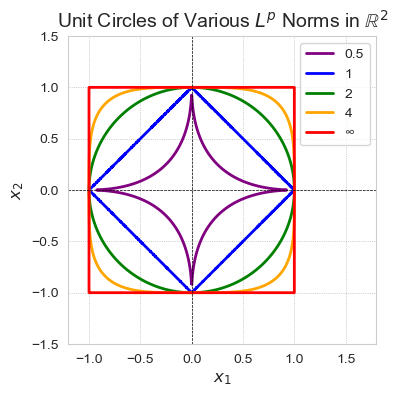

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a dense grid of x and y points
x = np.linspace(-1.5, 1.5, 1000)
y = np.linspace(-1.5, 1.5, 1000)
X, Y = np.meshgrid(x, y)

# Define the p-values and corresponding plotting parameters
p_values = [0.5, 1, 2, 4, np.inf]
labels = [
    # 'p = 0.5 (Quasi-norm)',
    # 'p = 1 (Manhattan / Taxicab)',
    # 'p = 2 (Euclidean)',
    # 'p = 4',
    # 'p = ∞ (Chebyshev / Maximum)'
    "0.5",
    "1",
    "2",
    "4",
    "∞",
]
colors = ["purple", "blue", "green", "orange", "red"]

plt.figure(figsize=(4, 4))

# Evaluate the norm over the grid and plot the level set at Z = 1
for p, label, color in zip(p_values, labels, colors):
    if p == np.inf:
        Z = np.maximum(np.abs(X), np.abs(Y))
    else:
        Z = (np.abs(X) ** p + np.abs(Y) ** p) ** (1 / p)

    # Plot the unit contour
    plt.contour(X, Y, Z, levels=[1], colors=color, linewidths=2)

    # Dummy plot for the legend (since contour returns a QuadContourSet)
    plt.plot([], [], color=color, label=label, linewidth=2)

# Format the plot
plt.axhline(0, color="black", linewidth=0.5, linestyle="--")
plt.axvline(0, color="black", linewidth=0.5, linestyle="--")
plt.grid(color="gray", linestyle=":", linewidth=0.5, alpha=0.7)
plt.gca().set_aspect("equal", adjustable="box")

plt.title("Unit Circles of Various $L^p$ Norms in $\\mathbb{R}^2$", fontsize=14)
plt.xlabel("$x_1$", fontsize=12)
plt.ylabel("$x_2$", fontsize=12)
plt.xlim(-1.2, 1.8)
plt.ylim(-1.5, 1.5)
plt.legend(loc="upper right", fontsize=10)

plt.savefig("lp_norms.png", dpi=300, bbox_inches="tight")

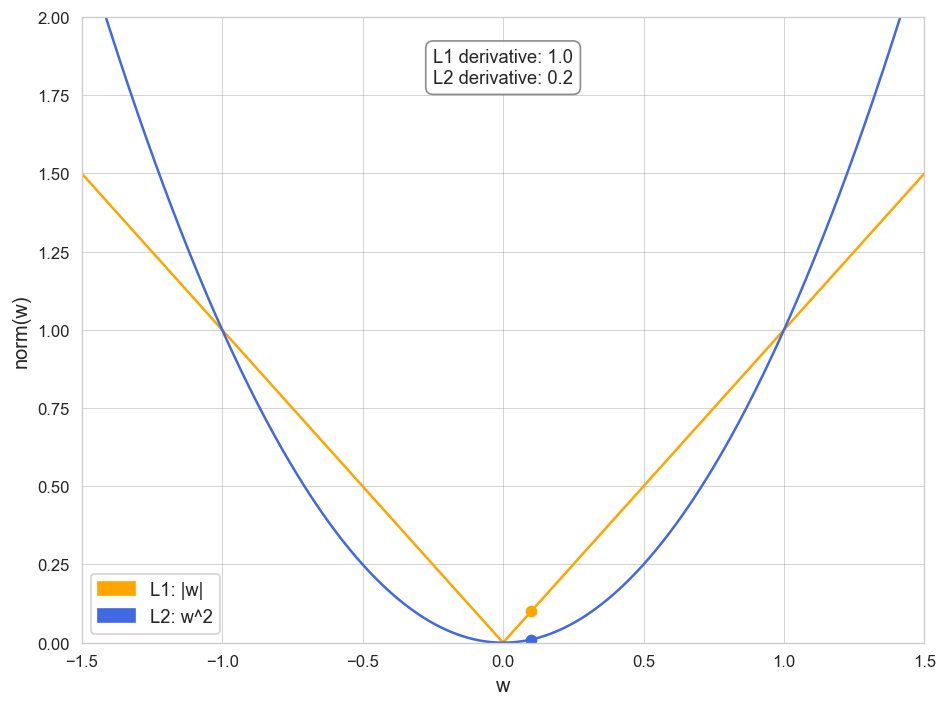

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Generate w values
w = np.linspace(-1.5, 1.5, 500)

# Define the penalty functions
l1 = np.abs(w)
l2_sq = w**2

# Point of evaluation for derivatives
w0 = 0.1
l1_w0 = np.abs(w0)
l2_sq_w0 = w0**2

# Calculate derivatives at w0 (for w > 0, d|w|/dw = 1, d(w^2)/dw = 2w)
l1_deriv = 1.0
l2_sq_deriv = 2 * w0

fig, ax = plt.subplots(figsize=(8, 6), dpi=120)

# Plot the penalty curves
ax.plot(w, l1, color="orange", linewidth=1.5)
ax.plot(w, l2_sq, color="royalblue", linewidth=1.5)

# Highlight the evaluation point w0 = 0.1
ax.plot(w0, l1_w0, "o", color="orange", markersize=6)
ax.plot(w0, l2_sq_w0, "o", color="royalblue", markersize=6)

# Text box for derivatives
textstr = f"L1 derivative: {l1_deriv:.1f}\nL2 derivative: {l2_sq_deriv:.1f}"
props = dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9, edgecolor="gray")
ax.text(
    0.5,
    0.95,
    textstr,
    transform=ax.transAxes,
    fontsize=11,
    verticalalignment="top",
    horizontalalignment="center",
    bbox=props,
)

# Custom legend using patches to match the reference image style
l1_patch = mpatches.Patch(color="orange", label="L1: |w|")
l2_patch = mpatches.Patch(color="royalblue", label="L2: w^2")
ax.legend(
    handles=[l1_patch, l2_patch],
    loc="lower left",
    fontsize=11,
    framealpha=1.0,
    edgecolor="lightgray",
)

# Formatting to match the reference
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(0, 2.0)
ax.set_xlabel("w", fontsize=12)
ax.set_ylabel("norm(w)", fontsize=12)

# Grid styling
ax.grid(color="gray", linestyle="-", linewidth=0.5, alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


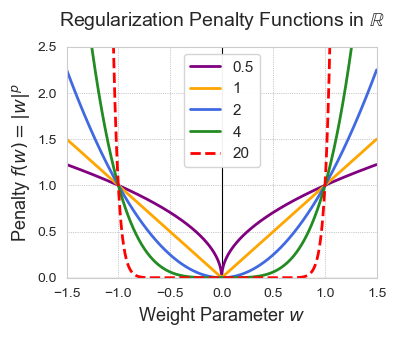

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the domain for the weight parameter
w = np.linspace(-1.5, 1.5, 1000)

# Define the p-values and their corresponding penalty functions f(w) = |w|^p
# We use p=20 to approximate the limiting behavior of p -> ∞
p_values = [0.5, 1, 2, 4, 20]
labels = [
    # '$p = 0.5$ (Quasi-norm)',
    # '$p = 1$ (Lasso)',
    # '$p = 2$ (Ridge)',
    # '$p = 4$',
    # '$p \\to \\infty$ (Box Constraint)'
    "0.5",
    "1",
    "2",
    "4",
    "20",
]
colors = ["purple", "orange", "royalblue", "forestgreen", "red"]
linestyles = ["-", "-", "-", "-", "--"]

fig, ax = plt.subplots(figsize=(4, 3))

# Plot each penalty function
for p, label, color, ls in zip(p_values, labels, colors, linestyles):
    # Calculate penalty
    penalty = np.abs(w) ** p

    # Clip the y-values to avoid plotting visual artifacts near infinity
    penalty = np.clip(penalty, a_min=None, a_max=3.0)

    # Plot
    ax.plot(w, penalty, label=label, color=color, linestyle=ls, linewidth=2)

# Plot formatting to meet academic standards
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(0, 2.5)

# Use mathematically precise axis labels
ax.set_xlabel("Weight Parameter $w$", fontsize=13)
ax.set_ylabel("Penalty $f(w) = |w|^p$", fontsize=13)
ax.set_title("Regularization Penalty Functions in $\\mathbb{R}$", fontsize=14, pad=15)

# Add origin axes for clarity
ax.axhline(0, color="black", linewidth=0.8, zorder=1)
ax.axvline(0, color="black", linewidth=0.8, zorder=1)

# Grid and Legend
ax.grid(color="gray", linestyle=":", linewidth=0.5, alpha=0.8)
ax.legend(loc="upper center", fontsize=11, framealpha=0.95, edgecolor="lightgray")

plt.savefig("norm_penalties.png", dpi=300, bbox_inches="tight")
